In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import numpy as np
from scipy.stats import qmc
from scipy.stats import t as stuent_t
import matplotlib.pyplot as plt
from corner import corner, overplot_lines, overplot_points

from utils.linear_model import get_ODR, get_OLS, xy2logxy

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10**(k * np.log10(x) + b + np.random.normal(0, sig, size=N))
# add outliers
selected = np.random.choice(N, 1000, replace=False)
y[selected] = 10**(-k * np.log10(x[selected]) + b +
                   np.random.normal(0, sig, size=1000))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:39: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:40: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)
2026-11-24 20:05:30.990737: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

(-50.0, 100.0)

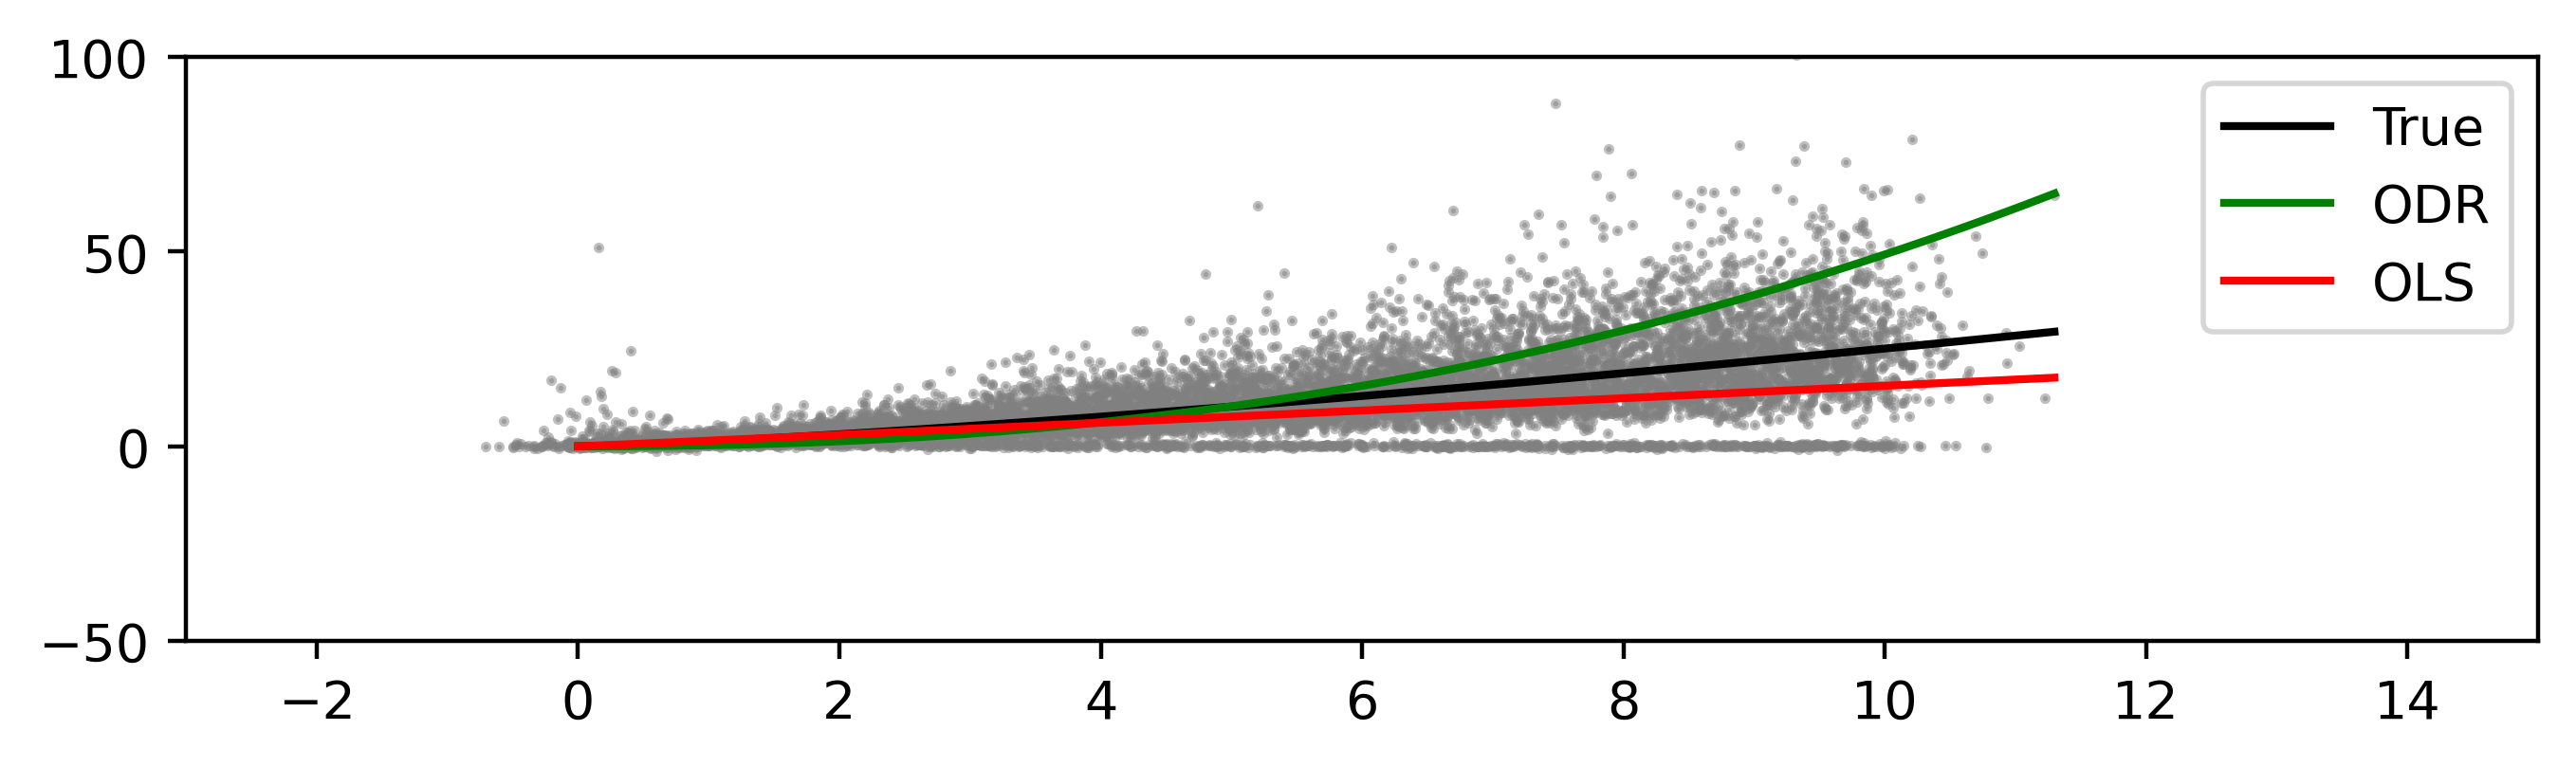

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

plt.xlim(-3, 15)
plt.ylim(-50, 100)

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LogLinearML, LogLinearKS, LogLinearStudentTML
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:06<10:09,  6.16s/it]

  7%|▋         | 7/100 [00:06<01:01,  1.52it/s]

 14%|█▍        | 14/100 [00:06<00:23,  3.65it/s]

 21%|██        | 21/100 [00:06<00:12,  6.47it/s]

 27%|██▋       | 27/100 [00:06<00:07,  9.52it/s]

... (11 outputs left out)

step 0: loss 1.447687029838562


step 10: loss 1.4350917339324951
step 20: loss 1.432504415512085


step 30: loss 1.4320460557937622
step 40: loss 1.428037405014038


step 50: loss 1.432693362236023
step 60: loss 1.433613657951355


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.011749974451959133, 0.7598265908967357)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:02,  5.48s/it]

  8%|▊         | 8/100 [00:05<00:47,  1.95it/s]

 15%|█▌        | 15/100 [00:05<00:19,  4.31it/s]

 22%|██▏       | 22/100 [00:05<00:10,  7.41it/s]

 29%|██▉       | 29/100 [00:05<00:06, 11.33it/s]

... (11 outputs left out)

step 0: loss 2.7076001167297363
step 10: loss 2.5705273151397705


step 20: loss 2.5450730323791504
step 30: loss 2.5331850051879883


step 40: loss 2.5234546661376953
step 50: loss 2.5189924240112305


step 60: loss 2.515399217605591
step 70: loss 2.515699863433838


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.016450010240077972, 0.3417798169980429)

### Normal Model

In [ ]:
logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0145625 0.01860323 0.17525753 -4.115687


1000 1.1007451 0.091229096 0.48329082 -2.5445468


2000 1.1160173 0.08100535 0.48319894 -2.544206


3000 1.1269063 0.07371221 0.4830579 -2.5440323


4000 1.13468 0.06850168 0.48298097 -2.543944


5000 1.1402359 0.06477593 0.4829357 -2.5438988


6000 1.144209 0.062110297 0.4829066 -2.5438757


7000 1.147052 0.060202256 0.48289168 -2.5438638


8000 1.1490885 0.058836054 0.4828823 -2.543858


9000 1.1505443 0.05785798 0.48287636 -2.5438547
converged, so stop with 9000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.1505443 0.05785798 0.48287636
Truth: 1.3 0.1 0.2


### T Model

In [ ]:
logLinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = logLinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0033654 0.004585575 1.9996878 0.11037472 -3.1636631


1000 1.2421664 0.12944992 1.9720567 0.18739761 -2.2201881


2000 1.2875224 0.097471215 1.9448905 0.1854999 -2.2161944


3000 1.3074198 0.08346292 1.9186374 0.18433942 -2.2148793


4000 1.3161665 0.07736219 1.8933778 0.18336205 -2.2141192


5000 1.3200155 0.07473948 1.8691362 0.18245047 -2.2135072


... (28 outputs left out)

34000 1.3230257 0.07413032 1.5428551 0.16939196 -2.2087226


35000 1.3230257 0.074143246 1.5399687 0.16926707 -2.2087147


36000 1.3230257 0.074155055 1.5373298 0.16915236 -2.208708


37000 1.3230257 0.074165866 1.5349175 0.16904722 -2.2087007
converged, so stop with 37000 iterations


In [ ]:
print('ML fitted:', *params_ml_t)
print('Truth:', k, b, sig)

ML fitted: 1.3230257 0.074165866 1.5349175 0.16904722
Truth: 1.3 0.1 0.2


In [ ]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.24357943391353135

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.367 +/- 0.120
b: -0.015 +/- 0.078
sig: 0.273 +/- 0.045


----
k: 1.421 +/- 0.131
b: -0.063 +/- 0.102
sig: 0.327 +/- 0.067


----
k: 1.426 +/- 0.142
b: -0.063 +/- 0.105
sig: 0.313 +/- 0.068


----
k: 1.448 +/- 0.141
b: -0.079 +/- 0.101
sig: 0.315 +/- 0.069


----
k: 1.448 +/- 0.155
b: -0.078 +/- 0.111
sig: 0.314 +/- 0.074


... (3 outputs left out)

----
k: 1.446 +/- 0.151
b: -0.077 +/- 0.109
sig: 0.315 +/- 0.069


----
k: 1.427 +/- 0.152
b: -0.063 +/- 0.106
sig: 0.318 +/- 0.070


----
k: 1.440 +/- 0.147
b: -0.068 +/- 0.106
sig: 0.319 +/- 0.073
max iteration reached


[ 1.44132031 -0.07146111  0.31481471] [0.14428353 0.10527269 0.06907225]


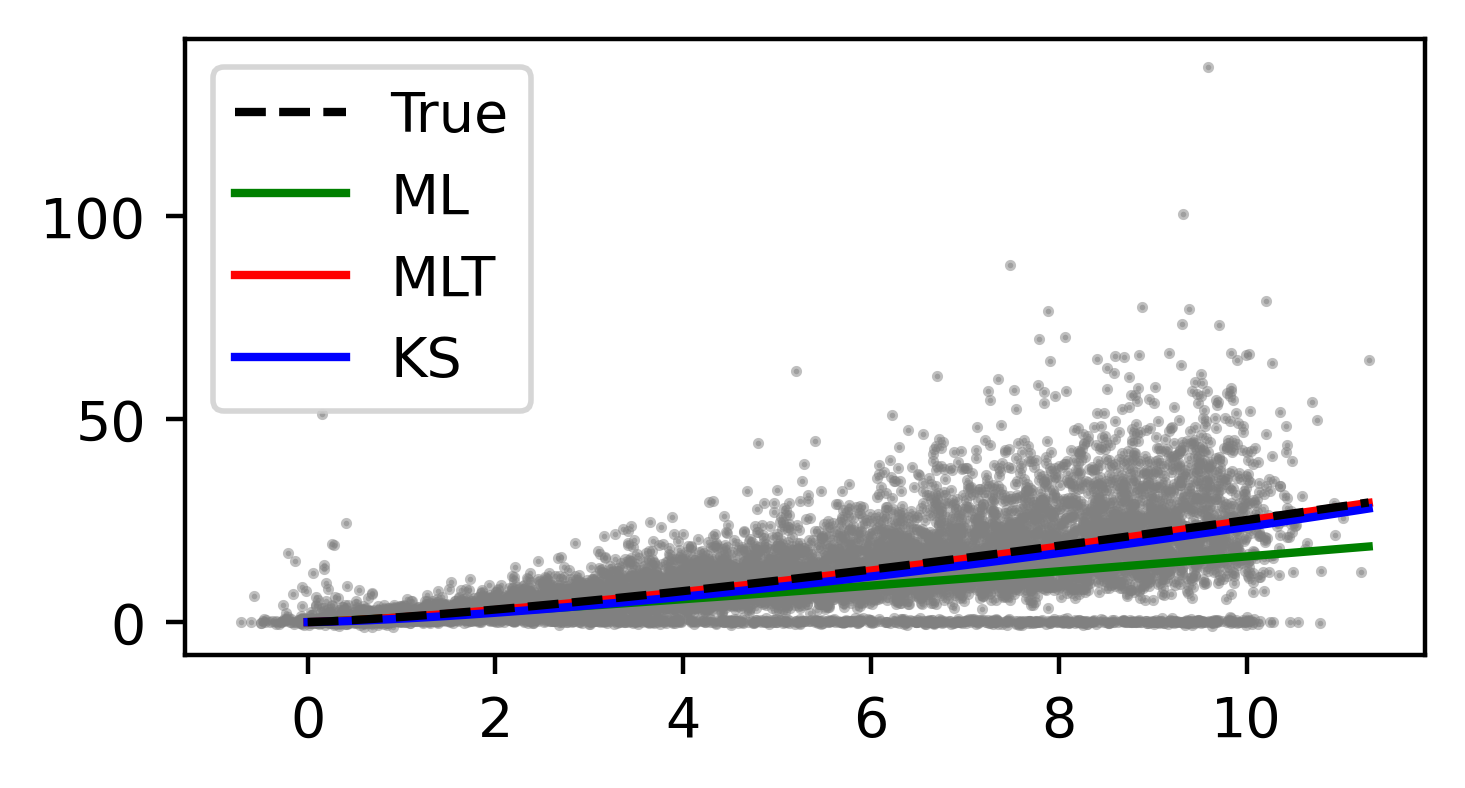

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')

plt.legend()